| 요구되는 내용 | 현재 분석 | 판단 |
|---|---|---|
| 피크의 크기와 분포 파악 | 일 최대전력의 월별 분포 | 수행 |
| 피크와 관련된 주요 조건 | 기상·일생산량 회귀 | 부분 충족 |
| 피크 발생 시점의 생산·가동 조건 | 현재 파일에는 해당 비교가 없음 | 보완 필요 |
| 생산일정·가동 시점 조정 방안 | 구체적인 조정 대상과 근거가 없음 | 보완 필요 |

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import subprocess, sys
subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "koreanize-matplotlib"])

import pandas as pd
import matplotlib.pyplot as plt
import koreanize_matplotlib  # 한글 폰트
from IPython.display import display

POWER = ["15분", "30분", "45분", "60분"]

df = pd.read_csv("/content/drive/MyDrive/kamp_2026/data/okm_augumented_2021.csv", encoding="utf-8-sig")
df = df.loc[df["시간"].between(0, 23)]  # 손상 행(시간 ∉ 0~23) 제외
date = pd.to_datetime(df["날짜"].astype(str), format="%Y%m%d")

weekday = df.loc[date.dt.dayofweek < 5]  # 월~금
daily_max = weekday[POWER].max(axis=1).groupby(weekday["날짜"]).max().rename("일최대").to_frame()
daily_max["월"] = daily_max.index // 100 % 100

display(daily_max.groupby("월")["일최대"].describe().round(1))

months = sorted(daily_max["월"].unique())
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.boxplot([daily_max.loc[daily_max["월"].eq(m), "일최대"] for m in months], positions=months, widths=.5, showfliers=False)
for m in months:
    values = daily_max.loc[daily_max["월"].eq(m), "일최대"]
    ax.scatter(m + (pd.Series(range(len(values))) / len(values) - .5) * .3, values, s=14, alpha=.6)
ax.set_xticks(months, [f"{m}월" for m in months])
ax.set_ylabel("평일 일 최대 (15분 전력)")
ax.set_title("월별 평일 일 최대 분포")
plt.tight_layout()
plt.show()


In [3]:
# # 복제일 제외: 1~4월은 5월 이후 곡선의 복제 → 5/1 이후만 사용
# # 5/1 이후에도 하루 96개 15분 값이 완전히 같은 날이 있으면, 생산 0인데 전력이 기저 부하보다 높은 시간이 가장 적은 1일만 남김
# import numpy as np
# from scipy.signal import argrelextrema
# from scipy.stats import gaussian_kde

# power15 = df[POWER].to_numpy(dtype=float).ravel()
# grid = np.linspace(0, power15.max(), 500)
# density = gaussian_kde(power15, bw_method=0.05)(grid)
# valleys = grid[argrelextrema(density, np.less, order=10)[0]]
# base_mode = grid[np.argmax(np.where(grid < np.median(power15), density, -np.inf))]  # 기저 부하 최빈값
# BASE_CUT = valleys[valleys > base_mode].min()  # 기저 부하 경계: 기저 봉우리 바로 위 골짜기

# after = df.loc[df["날짜"] >= 20210501].sort_values(["날짜", "시간"])
# curve = after.groupby("날짜")[POWER].apply(lambda day: tuple(day.to_numpy().ravel()))  # 날짜별 15분 값 96개
# mismatch = (after["생산량"].eq(0) & after[POWER].mean(axis=1).gt(BASE_CUT)).groupby(after["날짜"]).sum()
# native = mismatch.groupby(curve).idxmin()  # 같은 곡선 그룹마다 1일
# native_max = daily_max.loc[daily_max.index.isin(native)]
# print(f"평일 {len(daily_max)}일 → 복제일 제외 후 {len(native_max)}일")

# display(native_max.groupby("월")["일최대"].describe().round(1))

# months = sorted(native_max["월"].unique())
# fig, ax = plt.subplots(figsize=(11, 4.5))
# ax.boxplot([native_max.loc[native_max["월"].eq(m), "일최대"] for m in months], positions=months, widths=.5, showfliers=False)
# for m in months:
#     values = native_max.loc[native_max["월"].eq(m), "일최대"]
#     ax.scatter(m + (pd.Series(range(len(values))) / len(values) - .5) * .3, values, s=14, alpha=.6)
# ax.set_xticks(months, [f"{m}월" for m in months])
# ax.set_ylabel("평일 일 최대 (15분 전력)")
# ax.set_title("월별 평일 일 최대 분포 (복제일 제외)")
# plt.tight_layout()
# plt.show()

In [4]:
# import numpy as np

# curve_all = df.sort_values(["날짜", "시간"]).groupby("날짜")[POWER].apply(lambda day: tuple(day.to_numpy().ravel()))  # 날짜별 15분 값 96개
# month_all = curve_all.index // 100 % 100
# display(pd.DataFrame({"일수": curve_all.groupby(month_all).size(),
#                       "곡선이 다른 날과 완전히 같은 날": curve_all.duplicated(keep=False).groupby(month_all).sum()}).T)

# early = curve_all.index < 20210501
# late_curves = set(curve_all[~early])
# copied = curve_all[early].map(lambda day: day in late_curves)
# print(f"1~4월 {early.sum()}일 중 5월 이후 날과 곡선 전체가 같은 날 {copied.sum()}일")

평일 가동일 156일 (복제일 포함 평일 181일 중)


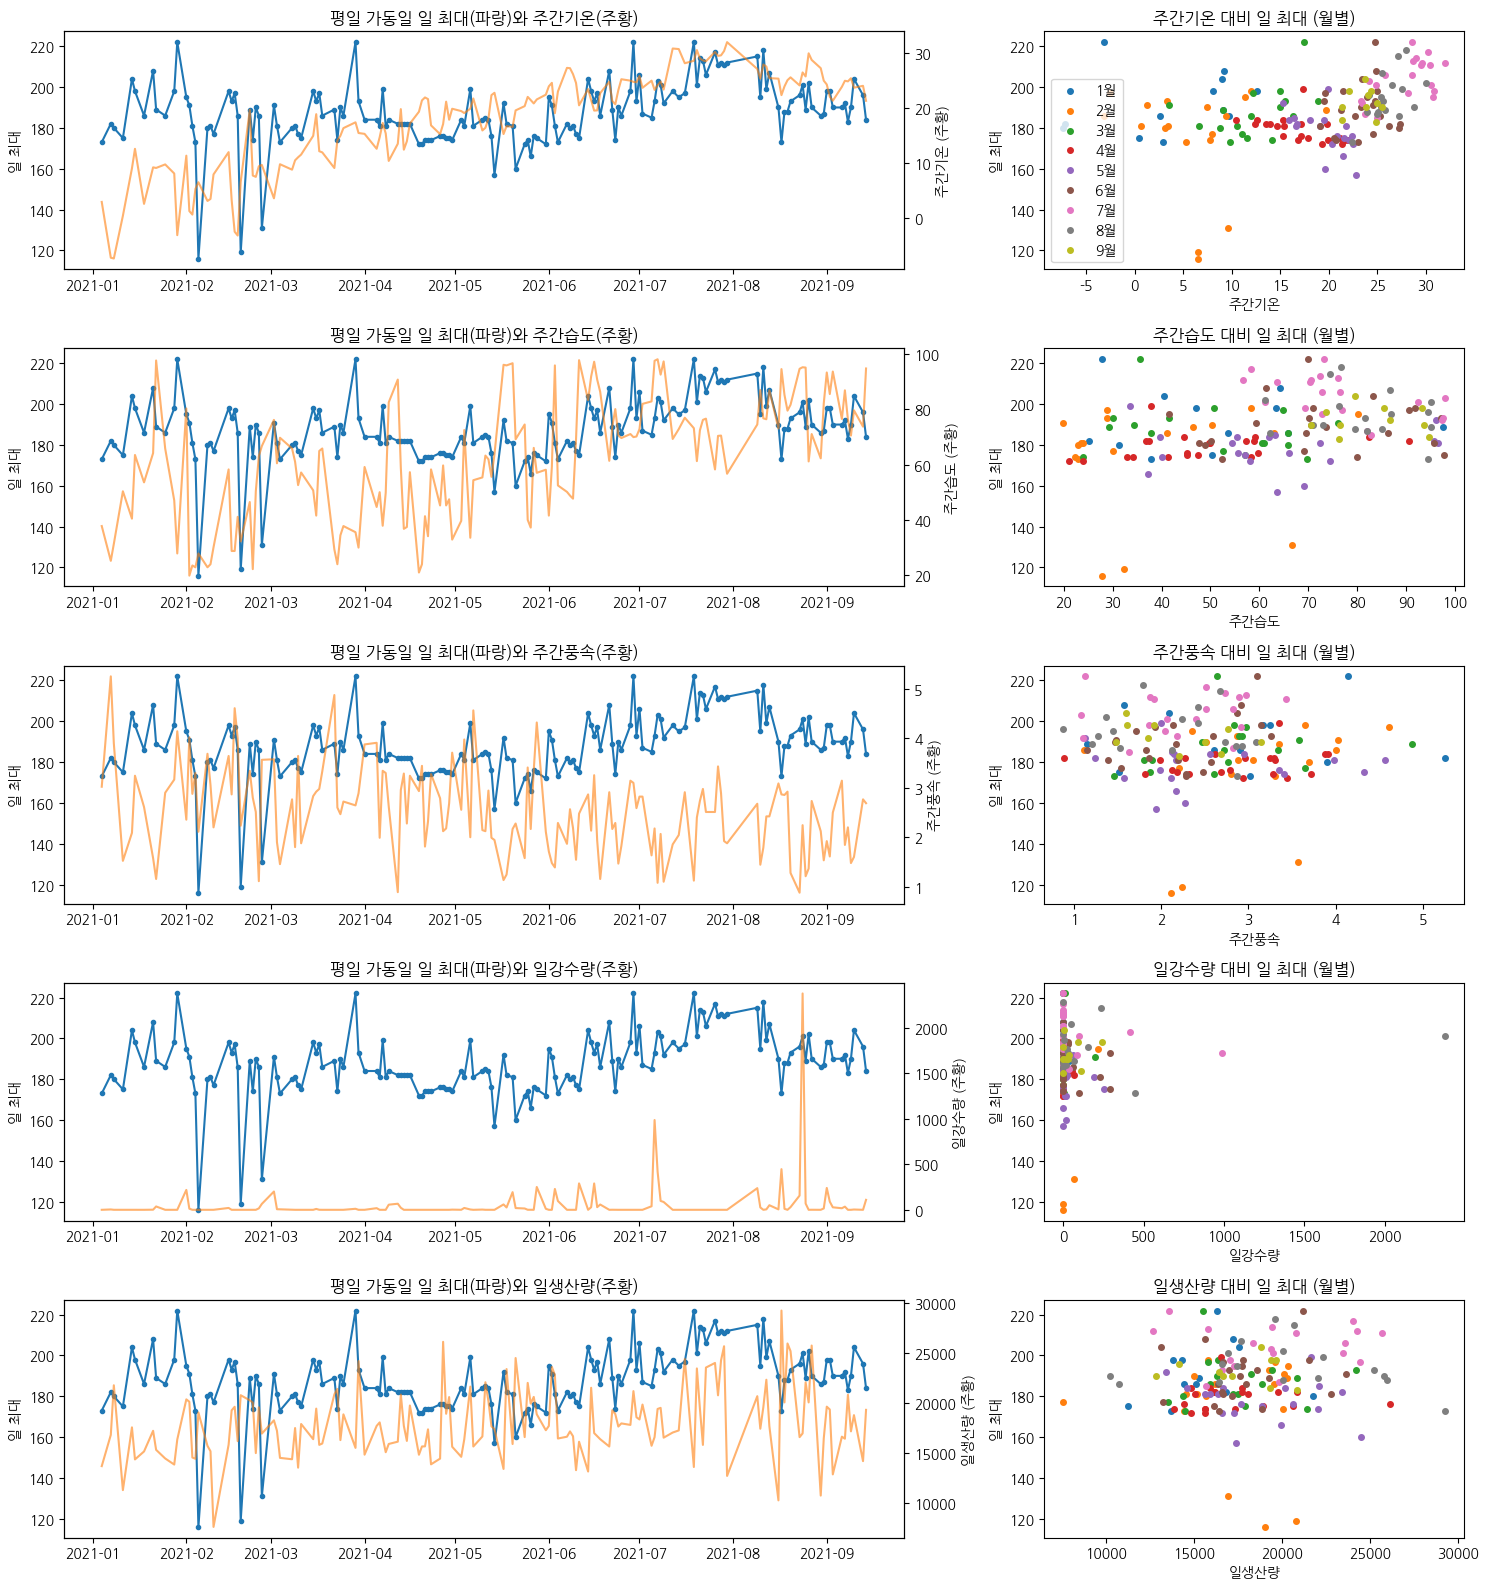

In [ ]:
daytime = df.loc[df["시간"].between(8, 16)]
op = daily_max.join(daytime.groupby("날짜")[["기온", "습도", "풍속"]].mean().add_prefix("주간"))  # 8~16시 평균
op["일강수량"] = df.groupby("날짜")["강수량"].sum()
op["일생산량"] = df.groupby("날짜")["생산량"].sum()
op = op.loc[daytime["생산량"].gt(0).groupby(daytime["날짜"]).sum().reindex(op.index).ge(5)]
op["주"] = pd.to_datetime(op.index.astype(str), format="%Y%m%d").isocalendar().week.to_numpy()
dates = pd.to_datetime(op.index.astype(str), format="%Y%m%d")
FEATURES = ["주간기온", "주간습도", "주간풍속", "일강수량", "일생산량"]
print(f"평일 가동일 {len(op)}일 (복제일 포함 평일 {len(daily_max)}일 중)")

fig, axes = plt.subplots(len(FEATURES), 2, figsize=(15, 3.2 * len(FEATURES)), gridspec_kw={"width_ratios": [2, 1]})
for (line_ax, scatter_ax), feature in zip(axes, FEATURES):
    line_ax.plot(dates, op["일최대"], marker="o", ms=3)
    line_ax.set_ylabel("일 최대")
    twin = line_ax.twinx()
    twin.plot(dates, op[feature], color="tab:orange", alpha=.6)
    twin.set_ylabel(f"{feature} (주황)")
    line_ax.set_title(f"평일 가동일 일 최대(파랑)와 {feature}(주황)")
    for m in sorted(op["월"].unique()):
        sel = op["월"].eq(m)
        scatter_ax.scatter(op.loc[sel, feature], op.loc[sel, "일최대"], s=16, label=f"{m}월")
    scatter_ax.set_xlabel(feature)
    scatter_ax.set_ylabel("일 최대")
    scatter_ax.set_title(f"{feature} 대비 일 최대 (월별)")
axes[0, 1].legend()
plt.tight_layout()
plt.show()

In [13]:
# 기본 다중선형회귀: 일 최대전력 ~ 기온 + 습도 + 풍속 + 강수량 + 생산량 (절편 포함)
# 날짜순 OLS + HAC 표준오차. 시차는 statsmodels 기본 규칙으로 자동 선택한다.
import numpy as np
import statsmodels.formula.api as smf

ols_data = op[["일최대"] + FEATURES].sort_index()
ols_model = smf.ols("일최대 ~ " + " + ".join(FEATURES), data=ols_data, missing="raise")
assert np.linalg.matrix_rank(ols_model.exog) == ols_model.exog.shape[1], "설명변수 간 완전한 선형종속이 있습니다."
ols_fit = ols_model.fit(cov_type="HAC", cov_kwds={"maxlags": None})
print(ols_fit.summary())

# 관측 자료의 조건부 관계이며 인과효과는 아니다. HAC는 중복 전력곡선 문제를 해소하지 않는다.


                            OLS Regression Results                            
Dep. Variable:                    일최대   R-squared:                       0.147
Model:                            OLS   Adj. R-squared:                  0.118
Method:                 Least Squares   F-statistic:                     2.905
Date:                Wed, 07 Oct 2026   Prob (F-statistic):             0.0156
Time:                        10:08:26   Log-Likelihood:                -638.99
No. Observations:                 156   AIC:                             1290.
Df Residuals:                     150   BIC:                             1308.
Df Model:                           5                                         
Covariance Type:                  HAC                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept    163.3452     10.140     16.109      0.0

평일 가동일 156일 / strucchange 기본 15% trimming / 후보 111개


,sup-F,p값 (Hansen 근사)
피처 5개,38.337405,0.000032


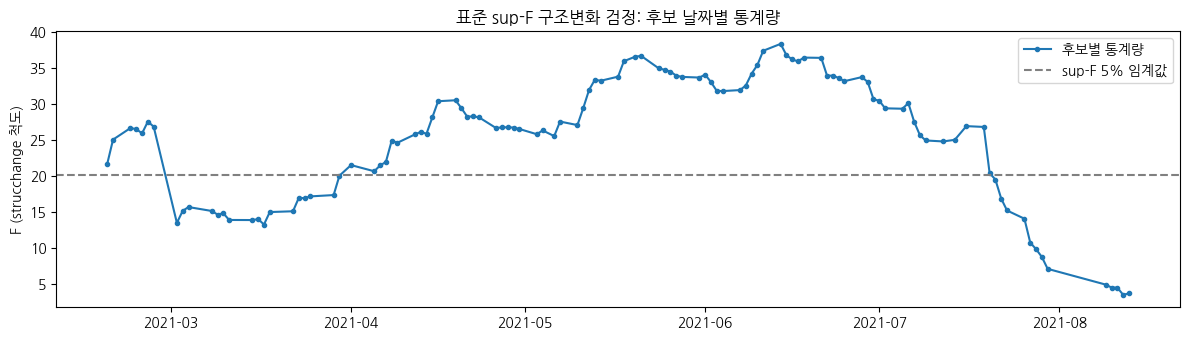

In [16]:
# 표준 sup-F 검정: 기존 strucchange 라이브러리 함수를 rpy2로 직접 호출
# 기본 15% trimming / Hansen 근사 p값. HAC 검정은 아니다.
import importlib.util
import shutil
import subprocess
import sys
import numpy as np

# Colab 환경 준비. 설치된 패키지는 재설치하지 않는다.
if shutil.which("R") is None:
    subprocess.check_call(["apt-get", "update", "-qq"])
    subprocess.check_call(["apt-get", "install", "-y", "-qq", "r-base-core", "r-cran-strucchange"])
if importlib.util.find_spec("rpy2") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "rpy2==3.6.8"])
from rpy2.robjects import DataFrame, FloatVector, Formula, StrVector
from rpy2.robjects.packages import importr, isinstalled
if not isinstalled("strucchange"):
    importr("utils").install_packages(StrVector(["strucchange"]), repos="https://cloud.r-project.org")
sc = importr("strucchange")
r_stats = importr("stats")

supf_data = op[["일최대"] + FEATURES].sort_index()
assert supf_data.index.is_unique and np.isfinite(supf_data.to_numpy(dtype=float)).all()
r_data = DataFrame({"y": FloatVector(supf_data["일최대"]),
                    **{f"x{i}": FloatVector(supf_data[name]) for i, name in enumerate(FEATURES)}})
fs = sc.Fstats(Formula("y ~ ."), data=r_data)
supf_test = sc.sctest(fs, type="supF")

# 패키지 결과를 출력과 그림에 사용할 수 있도록 변환
positions = np.rint(np.asarray(r_stats.time(fs.rx2("Fstats"))) * len(supf_data)).astype(int)
f_all = pd.Series(np.asarray(fs.rx2("Fstats")), index=positions)
base_supf = pd.Series({
    "sup-F": float(supf_test.rx2("statistic")[0]),
    "p값 (Hansen 근사)": float(supf_test.rx2("p.value")[0]),
})
results = base_supf.to_frame("피처 5개").T
print(f"평일 가동일 {len(supf_data)}일 / strucchange 기본 15% trimming / 후보 {len(f_all)}개")
display(results)

dates = pd.to_datetime(supf_data.index.astype(str), format="%Y%m%d")
fig, ax = plt.subplots(figsize=(12, 3.5))
ax.plot(dates[f_all.index], f_all, marker="o", ms=3, label="후보별 통계량")
ax.axhline(float(sc.boundary(fs, alpha=.05)[0]), color="gray", linestyle="--", label="sup-F 5% 임계값")
ax.legend()
ax.set_ylabel("F (strucchange 척도)")
ax.set_title("표준 sup-F 구조변화 검정: 후보 날짜별 통계량")
plt.tight_layout()
plt.show()


,sup-F,p값 (Hansen 근사)
피처 5개,38.337405,0.000032
+ 상호작용 10개,50.690962,0.000591


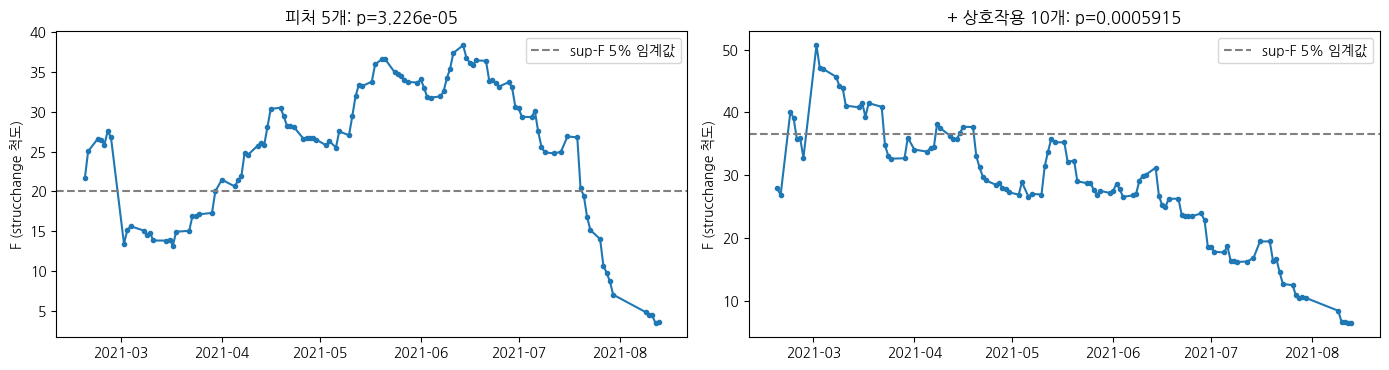

In [17]:
from itertools import combinations

# 상호작용 10개를 포함해 같은 라이브러리의 표준 sup-F 검정 호출
pairs = list(combinations(FEATURES, 2))
interaction_frame = supf_data.copy()
for a, b in pairs:
    interaction_frame[f"{a}×{b}"] = supf_data[a] * supf_data[b]
r_inter = DataFrame({"y": FloatVector(interaction_frame["일최대"]),
                     **{f"x{i}": FloatVector(interaction_frame[name])
                        for i, name in enumerate(interaction_frame.columns[1:])}})
fs_inter = sc.Fstats(Formula("y ~ ."), data=r_inter)
inter_test = sc.sctest(fs_inter, type="supF")
positions_inter = np.rint(np.asarray(r_stats.time(fs_inter.rx2("Fstats"))) * len(supf_data)).astype(int)
f_inter = pd.Series(np.asarray(fs_inter.rx2("Fstats")), index=positions_inter)
assert f_all.index.equals(f_inter.index), "두 모델의 경계 후보 범위가 다릅니다."
interaction_supf = pd.Series({
    "sup-F": float(inter_test.rx2("statistic")[0]),
    "p값 (Hansen 근사)": float(inter_test.rx2("p.value")[0]),
})
display(pd.DataFrame({"피처 5개": base_supf, "+ 상호작용 10개": interaction_supf}).T)

fig, axes = plt.subplots(1, 2, figsize=(14, 3.8))
for ax, label, curve, fitted, result in zip(axes, ["피처 5개", "+ 상호작용 10개"],
                                          [f_all, f_inter], [fs, fs_inter], [base_supf, interaction_supf]):
    ax.plot(dates[curve.index], curve, marker="o", ms=3)
    ax.axhline(float(sc.boundary(fitted, alpha=.05)[0]), color="gray", linestyle="--", label="sup-F 5% 임계값")
    ax.set_title(f"{label}: p={result['p값 (Hansen 근사)']:.4g}")
    ax.set_ylabel("F (strucchange 척도)")
    ax.legend()
plt.tight_layout()
plt.show()


BIC 선택: 경계 1개 / 구간 2개
경계 없음 BIC=1313.321, 선택 모형 BIC=1311.847
경계 수 선택은 기본 OLS/BIC, 아래 구간별 회귀의 표준오차는 HAC입니다.
구간을 같은 자료에서 선택했으므로 아래 신뢰구간·p값은 구간 선택의 불확실성을 반영하지 않은 탐색적 결과입니다.


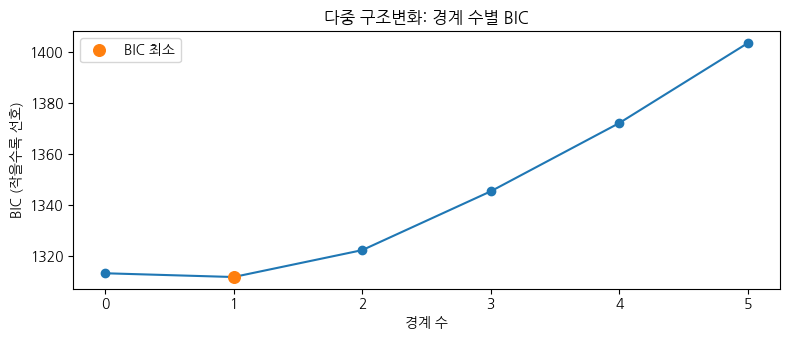


구간 1: 20210104~20210611 / 96일
                            OLS Regression Results                            
Dep. Variable:                    일최대   R-squared:                       0.033
Model:                            OLS   Adj. R-squared:                 -0.020
Method:                 Least Squares   F-statistic:                    0.8389
Date:                Wed, 07 Oct 2026   Prob (F-statistic):              0.526
Time:                        11:38:28   Log-Likelihood:                -395.09
No. Observations:                  96   AIC:                             802.2
Df Residuals:                      90   BIC:                             817.6
Df Model:                           5                                         
Covariance Type:                  HAC                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept    175.3478

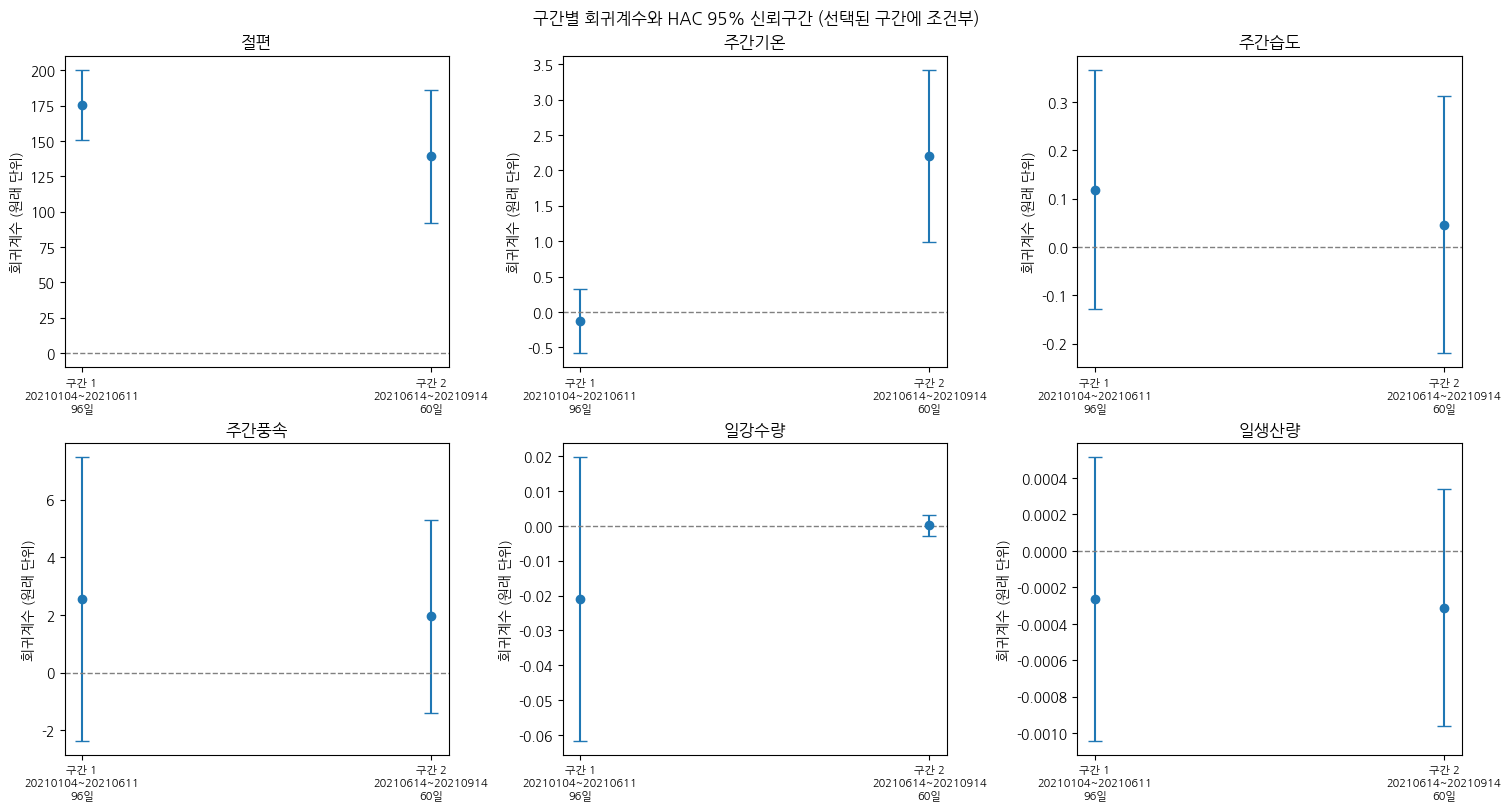

In [18]:
# 다중 구조변화: strucchange의 Bai–Perron 알고리즘 + BIC로 경계 수 선택
# 기본 피처 5개 / 최소 구간 크기는 패키지 기본값인 전체 관측치의 15%
# 앞의 sup-F 셀에서 만든 r_data, supf_data, sc를 사용한다.
import statsmodels.formula.api as smf

bp_full = sc.breakpoints(Formula("y ~ ."), data=r_data)
bp_selected = sc.breakpoints(bp_full)  # 경계 0개도 포함하여 BIC 최소 모형 선택
bp_summary = importr("base").summary(bp_full).rx2("RSS")
bp_bic = pd.Series(np.asarray(bp_summary)[list(bp_summary.rownames).index("BIC")],
                   index=np.asarray(bp_summary.colnames, dtype=int), name="BIC")
# R의 경계는 앞 구간의 관측치 수. 경계 없음(NA)은 빈 배열로 변환한다.
bp_raw = np.asarray(bp_selected.rx2("breakpoints"), dtype=float)
bp_splits = bp_raw[np.isfinite(bp_raw) & (bp_raw > 0)].astype(int)
bp_edges = np.r_[0, bp_splits, len(supf_data)]
print(f"BIC 선택: 경계 {len(bp_splits)}개 / 구간 {len(bp_edges) - 1}개")
print(f"경계 없음 BIC={bp_bic.loc[0]:.3f}, 선택 모형 BIC={bp_bic.loc[len(bp_splits)]:.3f}")
print("경계 수 선택은 기본 OLS/BIC, 아래 구간별 회귀의 표준오차는 HAC입니다.")
print("구간을 같은 자료에서 선택했으므로 아래 신뢰구간·p값은 구간 선택의 불확실성을 반영하지 않은 탐색적 결과입니다.")

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(bp_bic.index, bp_bic, marker="o")
ax.scatter(len(bp_splits), bp_bic.loc[len(bp_splits)], color="tab:orange", s=70, zorder=3, label="BIC 최소")
ax.set_xticks(bp_bic.index)
ax.set_xlabel("경계 수")
ax.set_ylabel("BIC (작을수록 선호)")
ax.set_title("다중 구조변화: 경계 수별 BIC")
ax.legend()
plt.tight_layout()
plt.show()

# 선택된 각 구간에서 같은 피처로 OLS + HAC(자동 시차) 회귀
segment_fits, segment_labels = [], []
for segment, (start, stop) in enumerate(zip(bp_edges[:-1], bp_edges[1:]), start=1):
    segment_data = supf_data.iloc[start:stop]
    segment_model = smf.ols("일최대 ~ " + " + ".join(FEATURES), data=segment_data, missing="raise")
    assert np.linalg.matrix_rank(segment_model.exog) == segment_model.exog.shape[1], "구간 내 설명변수가 완전히 선형종속입니다."
    segment_fit = segment_model.fit(cov_type="HAC", cov_kwds={"maxlags": None})
    segment_fits.append(segment_fit)
    segment_labels.append(f"구간 {segment}\n{segment_data.index[0]}~{segment_data.index[-1]}\n{len(segment_data)}일")
    print(f"\n구간 {segment}: {segment_data.index[0]}~{segment_data.index[-1]} / {len(segment_data)}일")
    print(segment_fit.summary())

fig, axes = plt.subplots(2, 3, figsize=(15, 8), constrained_layout=True)
for ax, feature in zip(axes.ravel(), ["Intercept"] + FEATURES):
    estimates = np.array([fit.params[feature] for fit in segment_fits])
    intervals = np.array([fit.conf_int().loc[feature].to_numpy() for fit in segment_fits])
    ax.errorbar(range(len(segment_fits)), estimates,
                yerr=np.vstack([estimates - intervals[:, 0], intervals[:, 1] - estimates]),
                fmt="o", capsize=5)
    ax.axhline(0, color="gray", linestyle="--", linewidth=1)
    ax.set_xticks(range(len(segment_fits)), segment_labels, fontsize=8)
    ax.set_title("절편" if feature == "Intercept" else feature)
    ax.set_ylabel("회귀계수 (원래 단위)")
fig.suptitle("구간별 회귀계수와 HAC 95% 신뢰구간 (선택된 구간에 조건부)")
plt.show()
# 한 구간에서만 유의하다는 사실은 구간 간 계수 차이가 유의하다는 뜻이 아니다.


In [33]:
# 기온 계수: 각 구간에서 0인지, 두 구간 사이에서 같은지 구분하여 검정
# 앞 셀의 BIC 선택 구간을 그대로 사용한다. 날짜를 직접 지정하지 않는다.
assert len(bp_splits) == 1, "이 셀은 경계 1개로 나뉜 두 구간의 전후 비교입니다."

print("구간별 기온 계수와 HAC 유의성 (귀무가설: 해당 구간의 기온 계수 = 0)")
temperature_by_segment = pd.DataFrame([
    {"기온 계수": fit.params["주간기온"], "HAC 표준오차": fit.bse["주간기온"],
     "p값": fit.pvalues["주간기온"],
     "95% 하한": fit.conf_int().loc["주간기온", 0],
     "95% 상한": fit.conf_int().loc["주간기온", 1]}
    for fit in segment_fits
], index=[label.replace("\n", " / ") for label in segment_labels])
display(temperature_by_segment)

# 절편과 모든 피처의 기울기가 전후로 달라질 수 있는 통합 회귀모형
# after:주간기온 = 뒤 구간 기온 계수 - 앞 구간 기온 계수
change_data = supf_data.copy()
change_data["after"] = (np.arange(len(change_data)) >= bp_splits[0]).astype(int)
change_model = smf.ols("일최대 ~ after * (" + " + ".join(FEATURES) + ")",
                       data=change_data, missing="raise")
assert np.linalg.matrix_rank(change_model.exog) == change_model.exog.shape[1], "설명변수가 완전히 선형종속입니다."
change_fit = change_model.fit(cov_type="HAC", cov_kwds={"maxlags": None})
print(change_fit.summary())


구간별 기온 계수와 HAC 유의성 (귀무가설: 해당 구간의 기온 계수 = 0)


,기온 계수,HAC 표준오차,p값,95% 하한,95% 상한
구간 1 / 20210104~20210611 / 96일,-0.133481,0.229798,0.561334,-0.583876,0.316914
구간 2 / 20210614~20210914 / 60일,2.205826,0.618622,0.000363,0.993349,3.418302


                            OLS Regression Results                            
Dep. Variable:                    일최대   R-squared:                       0.326
Model:                            OLS   Adj. R-squared:                  0.275
Method:                 Least Squares   F-statistic:                     11.43
Date:                Wed, 07 Oct 2026   Prob (F-statistic):           4.26e-15
Time:                        17:35:13   Log-Likelihood:                -620.57
No. Observations:                 156   AIC:                             1265.
Df Residuals:                     144   BIC:                             1302.
Df Model:                          11                                         
Covariance Type:                  HAC                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept    175.3478     12.877     13.617      0.0

피크·생산 최대 시간 일치 2/156일 / 피크 직후 생산 증가 93/156일


/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 8722 (\N{MINUS SIGN}) missing from font(s) NanumGothic.
  fig.canvas.print_figure(bytes_io, **kw)


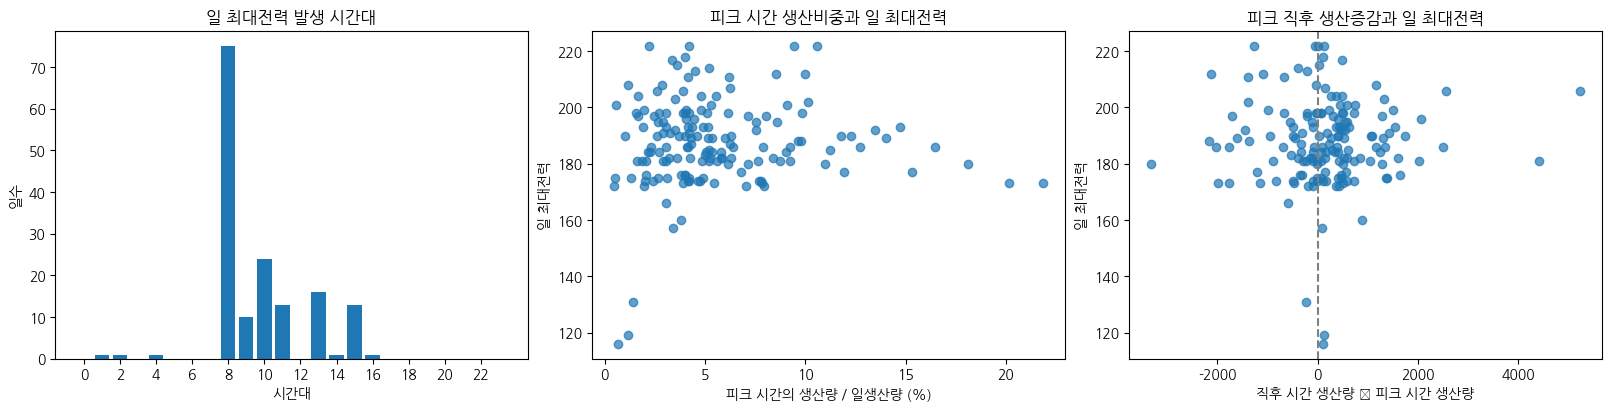

In [25]:
# ② 피크 발생 시각의 생산 상태: 시간별 생산량에 맞춰 일 최대가 나온 시간대를 연결
# 일 최대 동률은 가장 이른 시간대 선택. 23시의 직후 생산증감은 결측으로 둔다.
peak_daily = op[["일최대"] + FEATURES].sort_index().copy()
peak_hourly = df.loc[df["날짜"].isin(peak_daily.index)].sort_values(["날짜", "시간"]).copy()
peak_hourly["시간최대"] = peak_hourly[POWER].max(axis=1)
peak_hourly["직후생산증감"] = peak_hourly.groupby("날짜")["생산량"].shift(-1) - peak_hourly["생산량"]
peak_hourly["생산비중"] = 100 * peak_hourly["생산량"] / peak_hourly["날짜"].map(peak_daily["일생산량"])
peak_at = peak_hourly.loc[peak_hourly.groupby("날짜")["시간최대"].idxmax()].set_index("날짜").reindex(peak_daily.index)
peak_at["생산최대시간"] = peak_at["생산량"].eq(peak_hourly.groupby("날짜")["생산량"].max())
peak_counts = peak_at["시간"].value_counts().reindex(range(24), fill_value=0)
print(f"피크·생산 최대 시간 일치 {peak_at['생산최대시간'].sum()}/{len(peak_at)}일 / 피크 직후 생산 증가 {peak_at['직후생산증감'].gt(0).sum()}/{peak_at['직후생산증감'].notna().sum()}일")

fig, axes = plt.subplots(1, 3, figsize=(16, 4), constrained_layout=True)
axes[0].bar(peak_counts.index, peak_counts)
axes[0].set_xticks(range(0, 24, 2))
axes[0].set_xlabel("시간대")
axes[0].set_ylabel("일수")
axes[0].set_title("일 최대전력 발생 시간대")
axes[1].scatter(peak_at["생산비중"], peak_daily["일최대"], alpha=.7)
axes[1].set_xlabel("피크 시간의 생산량 / 일생산량 (%)")
axes[1].set_ylabel("일 최대전력")
axes[1].set_title("피크 시간 생산비중과 일 최대전력")
axes[2].scatter(peak_at["직후생산증감"], peak_daily["일최대"], alpha=.7)
axes[2].axvline(0, color="gray", linestyle="--")
axes[2].set_xlabel("직후 시간 생산량 − 피크 시간 생산량")
axes[2].set_ylabel("일 최대전력")
axes[2].set_title("피크 직후 생산증감과 일 최대전력")
plt.show()
# 기술통계이며, 피크 직후 생산량 증가만으로 예열·기동이 원인임을 입증하지 않는다.


In [32]:
# 시간당 최대 생산량과 일 최대전력: 같은 날짜의 최대값끼리 비교 (발생 시각은 달라도 됨)
import statsmodels.formula.api as smf

max_production_data = peak_daily[["일최대"] + FEATURES].copy()
max_production_data["시간최대생산량"] = peak_hourly.groupby("날짜")["생산량"].max()

# 기상조건·일생산량을 통제한 OLS + HAC. 시차는 날짜순 가동일 관측치 수로 자동 선택.
max_production_model = smf.ols("일최대 ~ " + " + ".join(FEATURES) + " + 시간최대생산량",
                               data=max_production_data, missing="raise")
assert np.linalg.matrix_rank(max_production_model.exog) == max_production_model.exog.shape[1], "설명변수가 완전히 선형종속입니다."
max_production_fit = max_production_model.fit(cov_type="HAC", cov_kwds={"maxlags": None})
print(max_production_fit.summary())
# 다른 피처를 통제한 조건부 관계이며 인과효과는 아니다.


                            OLS Regression Results                            
Dep. Variable:                    일최대   R-squared:                       0.169
Model:                            OLS   Adj. R-squared:                  0.135
Method:                 Least Squares   F-statistic:                     3.285
Date:                Wed, 07 Oct 2026   Prob (F-statistic):            0.00460
Time:                        17:34:55   Log-Likelihood:                -636.93
No. Observations:                 156   AIC:                             1288.
Df Residuals:                     149   BIC:                             1309.
Df Model:                           6                                         
Covariance Type:                  HAC                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept    165.3744      9.960     16.604      0.0

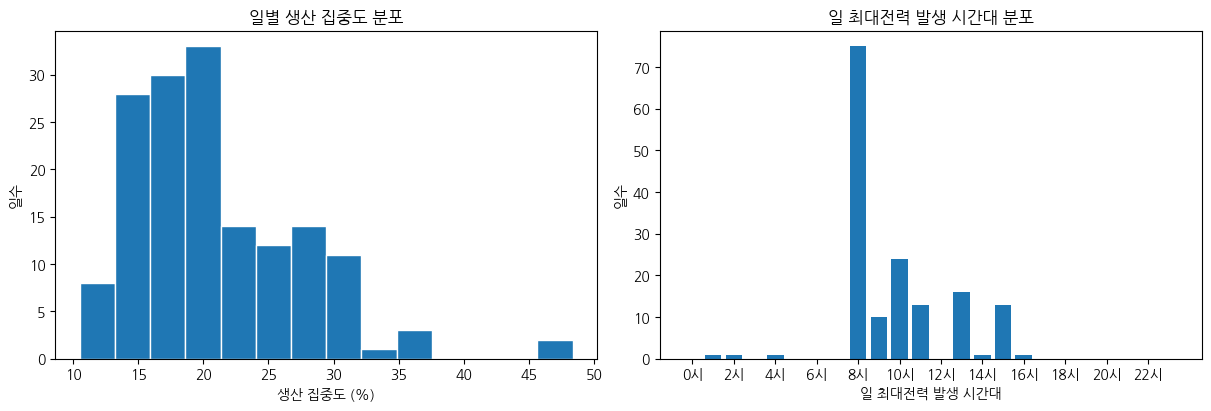

In [28]:
# ③ 일별 생산 집중도: 시간당 최대 생산량 / 일생산량 × 100 (%)
peak_daily["생산집중도"] = 100 * peak_hourly.groupby("날짜")["생산량"].max() / peak_daily["일생산량"]
assert peak_daily["생산집중도"].between(100 / 24, 100).all()
fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
axes[0].hist(peak_daily["생산집중도"], bins="auto", edgecolor="white")
axes[0].set_xlabel("생산 집중도 (%)")
axes[0].set_ylabel("일수")
axes[0].set_title("일별 생산 집중도 분포")
# 앞 셀의 일 최대 발생 시간 집계 사용 (동률이면 가장 이른 시간대)
axes[1].bar(peak_counts.index, peak_counts)
axes[1].set_xticks(range(0, 24, 2), [f"{hour}시" for hour in range(0, 24, 2)])
axes[1].set_xlabel("일 최대전력 발생 시간대")
axes[1].set_ylabel("일수")
axes[1].set_title("일 최대전력 발생 시간대 분포")
plt.show()


In [31]:
# ④ 생산 집중도와 일 최대전력: 기존 피처 5개를 통제한 OLS + HAC
# 계수는 생산 집중도 1%p 차이에 대응한다. 실제 사용량·생산량의 동시적 관계이며 인과효과가 아니다.
# HAC 시차는 날짜순 가동일 관측치 기준으로 자동 선택한다(달력 일수 간격 아님).
import statsmodels.formula.api as smf

concentration_model = smf.ols("일최대 ~ " + " + ".join(FEATURES) + " + 생산집중도", data=peak_daily, missing="raise")
assert np.linalg.matrix_rank(concentration_model.exog) == concentration_model.exog.shape[1], "설명변수가 완전히 선형종속입니다."
concentration_fit = concentration_model.fit(cov_type="HAC", cov_kwds={"maxlags": None})
print(concentration_fit.summary())
# 집중도 계수의 HAC z검정이 주 검정이며, 일반 OLS의 잔차 기반 F검정으로 대체하지 않는다.


                            OLS Regression Results                            
Dep. Variable:                    일최대   R-squared:                       0.170
Model:                            OLS   Adj. R-squared:                  0.136
Method:                 Least Squares   F-statistic:                     3.434
Date:                Wed, 07 Oct 2026   Prob (F-statistic):            0.00332
Time:                        17:34:12   Log-Likelihood:                -636.85
No. Observations:                 156   AIC:                             1288.
Df Residuals:                     149   BIC:                             1309.
Df Model:                           6                                         
Covariance Type:                  HAC                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept    157.4193     10.386     15.157      0.0